# Korpus in Zahlen

Diagramme zum Bestand für Kapitel 8 des Berichts und für Präsentationen. Das Notebook liest die Datenbank der App nur lesend (`src/backend/leaflet_database.db`). `STIL` in der ersten Code-Zelle wählt die Fassung: `'doku'` in den Farben der Anwendung als PNG nach `docs/abbildungen/`, `'praesentation'` in den Folienfarben als PNG und SVG nach `output/praesentation/`.

Gezählt wird wie in der App und in `kennzahlen.md`: Jedes Flugblatt zählt einmal mit seinem Hauptexemplar, und nur freigegebene Bände gehen ein. Als Jahr gilt das Datum auf dem Blatt, sonst das Jahr des Bandes.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DB = Path('../src/backend/leaflet_database.db').resolve()
STIL = 'doku'  # or 'praesentation'
if STIL == 'doku':  # colors from src/frontend/static/styles.css
    OUT, SUFFIXES, FONT = Path('../docs/abbildungen'), ('png',), 'Segoe UI'
    MAIN, LIGHT, GREY, OTHER, INK, GRID = '#1e5aa8', '#a9c3e4', '#68707c', '#c9c4ba', '#3f4854', '#ddd9d1'
else:
    OUT, SUFFIXES, FONT = Path('../output/praesentation'), ('png', 'svg'), 'Arial'
    MAIN, LIGHT, GREY, OTHER, INK, GRID = '#DA3C43', '#F2B1B4', '#7A7A7A', '#BDBDBD', '#444444', '#E6E6E6'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': FONT,
    'figure.figsize': (10, 5.6), 'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 14, 'axes.titlesize': 18, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GREY,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'axes.axisbelow': True,
    'xtick.color': INK, 'ytick.color': INK, 'text.color': INK, 'axes.labelcolor': INK, 'legend.frameon': False,
})


def save(fig, name):
    for suffix in SUFFIXES:
        fig.savefig(OUT / f'{name}.{suffix}')


def de(n):
    return f'{n:,}'.replace(',', '.')

In [2]:
con = sqlite3.connect(f'file:{DB.as_posix()}?mode=ro', uri=True)
segments = pd.read_sql('''
    SELECT l.id, l.start_page, l.end_page, l.date_iso, l.doc_type, l.copy_group, l.canonical_leaflet_id,
           v.year AS band_year
    FROM leaflets l JOIN volumes v ON v.id = l.volume_id
    WHERE v.status = 'freigegeben' ''', con)
segments['main'] = segments.copy_group.isna() | (segments.canonical_leaflet_id == segments.id)
segments['dated'] = segments.date_iso.fillna('').str[:4].str.isdigit()
segments['year'] = segments.date_iso.str[:4].where(segments.dated, segments.band_year.astype(str)).astype(int)
segments['pages'] = segments.end_page - segments.start_page + 1
docs = segments[segments.main]
print(f'{de(len(segments))} Segmente, {de(len(docs))} Dokumente')

1.927 Segmente, 1.547 Dokumente


## 1 Verteilung pro Jahr

dated,True,False
year,,
1967,6,1
1968,17,33
1969,101,80
1970,86,87
1971,102,94
1972,219,263
1973,182,276


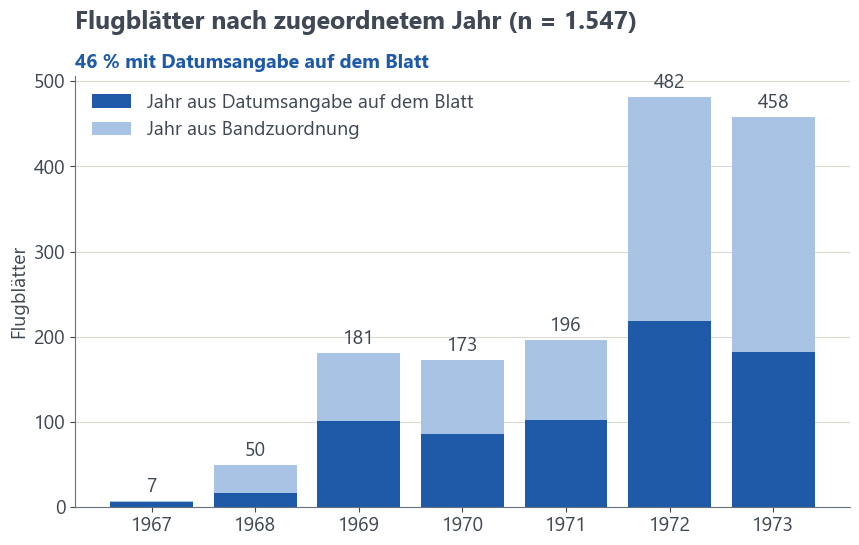

In [3]:
counts = docs.groupby(['year', 'dated']).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
fig, ax = plt.subplots()
ax.bar(counts.index, counts[True], color=MAIN, label='Jahr aus Datumsangabe auf dem Blatt')
ax.bar(counts.index, counts[False], bottom=counts[True], color=LIGHT, label='Jahr aus Bandzuordnung')
for year, total in counts.sum(axis=1).items():
    ax.text(year, total + 6, de(total), ha='center', va='bottom')
ax.set_title(f'Flugblätter nach zugeordnetem Jahr (n = {de(len(docs))})', pad=34)
ax.text(0, 1.02, f'{100 * docs.dated.mean():.0f} % mit Datumsangabe auf dem Blatt',
        transform=ax.transAxes, color=MAIN, fontsize=14, fontweight='bold')
ax.set_ylabel('Flugblätter')
ax.set_xticks(counts.index)
ax.legend(loc='upper left')
save(fig, '1_verteilung_jahr')
counts

## 2 Verteilung der Seitenlänge

count    1547.000000
mean        2.265029
std         2.890335
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max        42.000000
Name: pages, dtype: float64

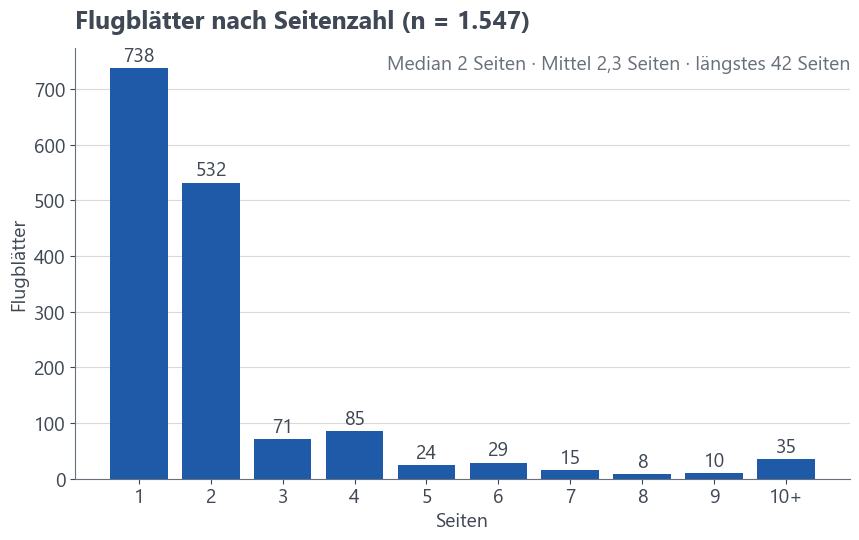

In [4]:
CAP = 10
dist = docs.pages.clip(upper=CAP).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(dist.index, dist.values, color=MAIN)
for pages, n in dist.items():
    ax.text(pages, n + 6, de(n), ha='center', va='bottom')
ax.set_xticks(dist.index, [str(p) if p < CAP else f'{CAP}+' for p in dist.index])
ax.set_title(f'Flugblätter nach Seitenzahl (n = {de(len(docs))})')
ax.set_xlabel('Seiten')
ax.set_ylabel('Flugblätter')
summary = f'Median {docs.pages.median():g} Seiten · Mittel {docs.pages.mean():.1f} Seiten · längstes {docs.pages.max()} Seiten'
ax.text(1, 0.95, summary.replace('.', ','), transform=ax.transAxes, ha='right', color=GREY)
save(fig, '2_seitenlaenge')
docs.pages.describe()

## 3 Mehrfachexemplare

Je Bandjahr. Ein weiteres Exemplar zählt im Jahr seines eigenen Bandes, das Hauptexemplar kann in einem anderen liegen.

,dokumente,segmente,weitere
band_year,,,
1967,6,6,0
1968,51,58,7
1969,184,212,28
1970,169,187,18
1971,196,230,34
1972,477,631,154
1973,464,603,139


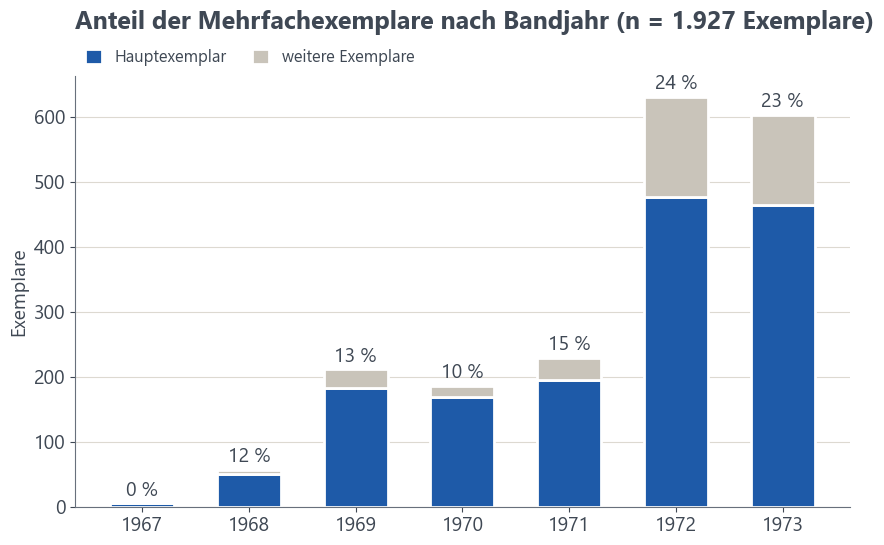

In [5]:
by_band = segments.groupby('band_year').main.agg(dokumente='sum', segmente='size')
by_band['weitere'] = by_band.segmente - by_band.dokumente
fig, ax = plt.subplots()
bar = {'width': 0.6, 'edgecolor': 'white', 'linewidth': 2}
ax.bar(by_band.index, by_band.dokumente, color=MAIN, label='Hauptexemplar', **bar)
ax.bar(by_band.index, by_band.weitere, bottom=by_band.dokumente, color=OTHER, label='weitere Exemplare', **bar)
for year, row in by_band.iterrows():
    ax.text(year, row.segmente + 6, f'{100 * row.weitere / row.segmente:.0f} %', ha='center', va='bottom')
total = by_band.weitere.sum() / by_band.segmente.sum()
ax.set_title(f'Anteil der Mehrfachexemplare nach Bandjahr (n = {de(len(segments))} Exemplare)', pad=34)
ax.set_ylabel('Exemplare')
ax.set_xticks(by_band.index)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=2, borderaxespad=0.2, fontsize=12,
          handlelength=1, handleheight=1, columnspacing=1.5)
save(fig, '3_mehrfachexemplare')
by_band

## 4 Herausgeber

Ein Dokument mit mehreren Herausgebern zählt bei jedem einmal.

label
Allgemeiner Studentenausschuss (AStA)              317
Ring Christlich-Demokratischer Studenten (RCDS)    133
Aktionsgemeinschaft liberaler Studenten (ALS)       66
Demokratische Mitte (DM)                            66
Marxistischer Studentenbund Spartakus (MSB)         60
Demokratische Front (DF)                            55
Fachschaft Wirtschaftswissenschaft                  54
Gewerkschaft Erziehung und Wissenschaft (GEW)       33
Marxistische Hochschulgruppe (MHG)                  30
Fachschaft Sprach- und Literaturwissenschaft        29
dtype: int64

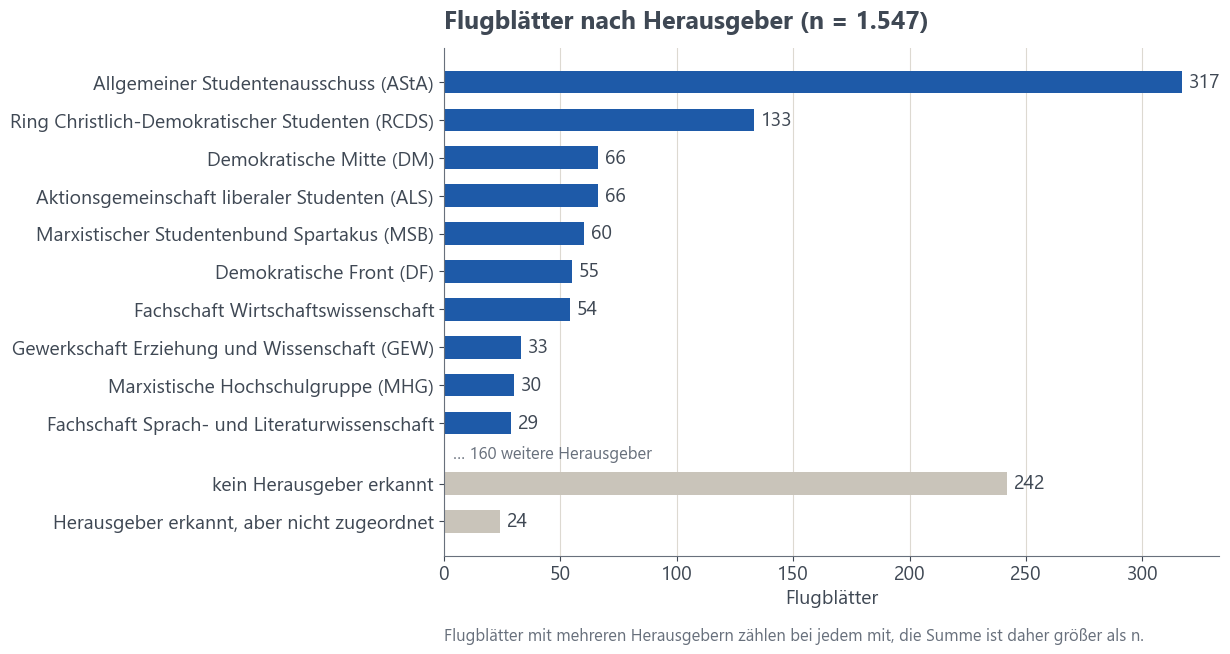

In [6]:
TOP = 10
issuers = pd.read_sql('''
    SELECT DISTINCT i.leaflet_id, o.id AS org_id, o.name, o.full_name
    FROM leaflet_issuers i JOIN organizations o ON o.id = i.org_id
    WHERE i.role = 'issuer' ''', con)
issuers = issuers[issuers.leaflet_id.isin(docs.id)]
issuers['label'] = [f'{full} ({name})' if full else name for name, full in zip(issuers.name, issuers.full_name)]
with_issuer = pd.read_sql("SELECT DISTINCT leaflet_id FROM leaflet_issuers WHERE role = 'issuer'", con).leaflet_id
no_issuer = (~docs.id.isin(with_issuer)).sum()
top = issuers.groupby('label').size().nlargest(TOP).sort_values()
fig, ax = plt.subplots(figsize=(10, 6.6))
unregistered = pd.read_sql("SELECT DISTINCT leaflet_id FROM leaflet_issuers WHERE role = 'issuer' AND org_id IS NULL",
                           con).leaflet_id.isin(docs.id).sum()
positions = [0, 1] + [2.6 + i for i in range(len(top))]
labels = ['Herausgeber erkannt, aber nicht zugeordnet', 'kein Herausgeber erkannt'] + list(top.index)
values = [unregistered, no_issuer] + list(top.values)
ax.barh(positions, values, color=[OTHER] * 2 + [MAIN] * len(top), height=0.6)
for y, n in zip(positions, values):
    ax.text(n + 3, y, de(n), va='center')
ax.set_yticks(positions, labels)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_title(f'Flugblätter nach Herausgeber (n = {de(len(docs))})')
ax.set_xlabel('Flugblätter')
counts = issuers.groupby('org_id').size().sort_values(ascending=False)
ax.text(4, 1.8, f'… {len(counts) - TOP} weitere Herausgeber', va='center', color=GREY, fontsize=12)
ax.text(0, -0.14, 'Flugblätter mit mehreren Herausgebern zählen bei jedem mit, die Summe ist daher größer als n.',
        transform=ax.transAxes, va='top', color=GREY, fontsize=12)
save(fig, '4_herausgeber')
top.sort_values(ascending=False)

## 5 Textsorte

doc_type
Flugblatt        1140
Einladung         186
Broschüre          83
Zeitschrift        42
Offener Brief      41
unklar             34
Protokoll          21
Name: count, dtype: int64

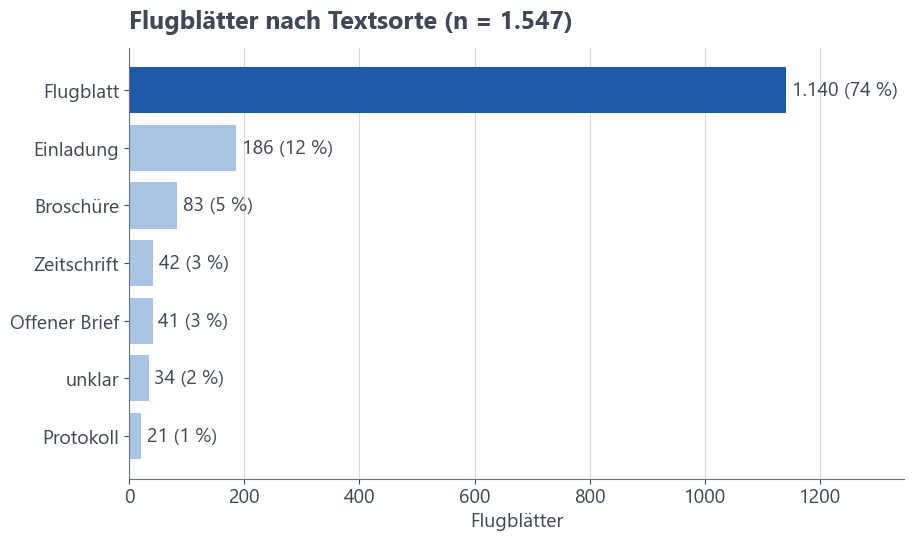

In [7]:
TYPES = {'flugblatt': 'Flugblatt', 'offener_brief': 'Offener Brief', 'einladung': 'Einladung',
         'broschuere': 'Broschüre', 'zeitschrift': 'Zeitschrift', 'protokoll': 'Protokoll', 'unklar': 'unklar'}
types = docs.doc_type.fillna('unklar').map(TYPES).value_counts().sort_values()
fig, ax = plt.subplots()
ax.barh(types.index, types.values, color=[MAIN if t == 'Flugblatt' else LIGHT for t in types.index])
for i, n in enumerate(types.values):
    ax.text(n + 10, i, f'{de(n)} ({100 * n / types.sum():.0f} %)', va='center')
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_title(f'Flugblätter nach Textsorte (n = {de(len(docs))})')
ax.set_xlabel('Flugblätter')
ax.set_xlim(0, types.max() * 1.18)
save(fig, '5_textsorte')
types.sort_values(ascending=False)

## 6 Seiten pro Jahr

Alle Seiten der Bände, mit Trennblättern und leeren Seiten, nach dem Jahr des Bandes.

,seiten,baende
year,,
1967,13,1
1968,85,1
1969,317,1
1970,294,1
1971,629,1
1972,1608,4
1973,1518,5


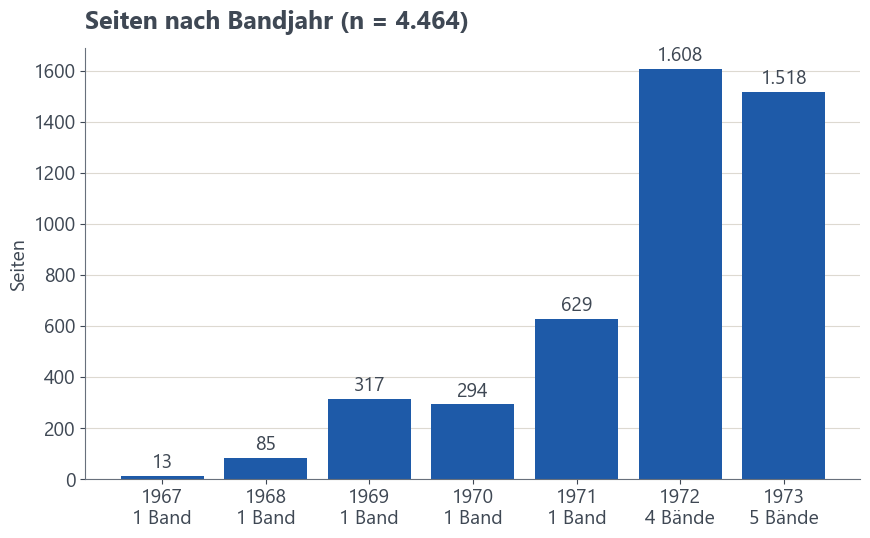

In [8]:
pages = pd.read_sql('''
    SELECT v.year, count(*) AS seiten, count(DISTINCT v.id) AS baende
    FROM pages p JOIN volumes v ON v.id = p.volume_id
    WHERE v.status = 'freigegeben' GROUP BY v.year''', con).set_index('year')
fig, ax = plt.subplots()
ax.bar(pages.index, pages.seiten, color=MAIN)
for year, row in pages.iterrows():
    ax.text(year, row.seiten + 15, de(row.seiten), ha='center', va='bottom')
ax.set_title(f'Seiten nach Bandjahr (n = {de(pages.seiten.sum())})')
ax.set_ylabel('Seiten')
ax.set_xticks(pages.index, [f'{y}\n{n} {"Band" if n == 1 else "Bände"}' for y, n in pages.baende.items()])
save(fig, '6_seiten_jahr')
pages

## 7 Geprüfte Fälle von Mehrfachexemplaren

Die Zahl der getrennten Blätter steht nicht in der Datenbank, sie ist von `/exemplare` übernommen (Einträge „Getrennt“, Stand 13.10.2026).

doch ein anderes Blatt     10
vier- oder fünffach         7
dreifach                   55
doppelt                   248
dtype: int64

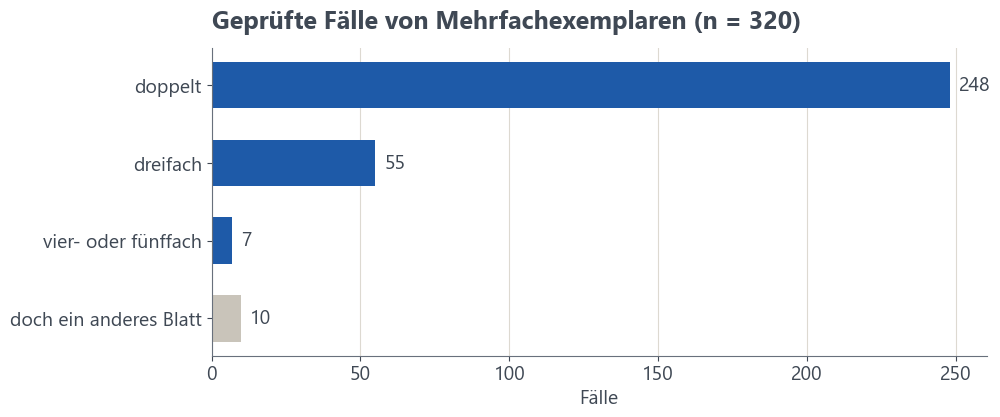

In [9]:
SPLIT_OFF = 10
sizes = segments[segments.copy_group.notna()].groupby('copy_group').size().value_counts()
cases = pd.Series({'doppelt': sizes.get(2, 0), 'dreifach': sizes.get(3, 0),
                   'vier- oder fünffach': sizes[sizes.index >= 4].sum(), 'doch ein anderes Blatt': SPLIT_OFF})[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(cases.index, cases.values, color=[OTHER] + [MAIN] * 3, height=0.6)
for i, n in enumerate(cases.values):
    ax.text(n + 3, i, de(n), va='center')
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_title(f'Geprüfte Fälle von Mehrfachexemplaren (n = {cases.sum()})')
ax.set_xlabel('Fälle')
save(fig, '7_exemplare_faelle')
cases